# Data generation 

I was thinking of starting with a **controlled synthetic dataset**, so we can use it later to explore causal inference, Bayesian uncertainty, explainability, and latent representation learning.

For example, imagine a machine where the **workload** affects both its operating **speed** and **energy consumption**. So, the question is: **If we deliberately change the operating speed, how much would the energy consumption actually change?**

Since we're generating the data, we know the underlying causal mechanism. This allows us to compare observational and interventional data, calculate the true causal effects, and verify the results mathematically.

Then, as we move forward, we can gradually introduce more complex conditions, like **hidden confounders, nonlinear relationships, latent variables, and distribution shifts**, and investigate how reliably different causal machine learning models perform under those conditions.


In [2]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
OUTPUT = Path("")
FIGURES = OUTPUT / "figures"
DATA = OUTPUT / "data"
FIGURES.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "pandas:", pd.__version__)

Python: 3.12.3
NumPy: 1.26.4 pandas: 2.3.2
Output folder: C:\Users\themi\Documents\GitHub\trustworthy-causal-modelling


## Our causal graph 

Three variables are involved:

- **\(U\)** — workload, measured *before* speed is selected. It is an **observed confounder**, because it affects both speed and energy use.
- **\(X\)** — operating speed, the variable an operator can deliberately set (the *treatment*).
- **\(Y\)** — energy consumption, the outcome.

Our **directed acyclic graph (DAG)** is,

```text
             U (workload)
            /            \\
           v              v
     X (speed)  -------> Y (energy)
```

The arrows are **assumed by design** because we generate the data. They are not discovered from the observed correlations.

A confounder creates a path $X \leftarrow U \rightarrow Y$, so observing high energy usage at high speed does not, by itself, tell us the effect of *setting* speed higher.

## Structural Causal Model (SCM)

A **Structural Causal Model** specifies each variable as a function of its causal parents and an external noise variable. For environment \(e\), we choose,

$$
U \sim \mathcal{N}(\mu_e, \sigma_e^2), \quad
\epsilon_X \sim \mathcal{N}(0,1), \quad
\epsilon_Y \sim \mathcal{N}(0,1)
$$

$$
X = 0.8U + \epsilon_X, \qquad
Y = 2X + 1.5U + 0.5XU + \epsilon_Y
$$

Here $\mathcal{N}(\mu, \sigma^2)$ means a **normal (Gaussian) distribution**, with mean $\mu$ and variance $\sigma^2$. All three exogenous random sources are mutually independent. This independence is one of our deliberate assumptions.

**Why each term?**

- \(0.8U\) makes workload influence speed, producing confounding.
- \(2X\) is the direct baseline effect of speed on energy use.
- \(1.5U\) lets workload affect energy consumption independently of speed.
- \(0.5XU\) is an **interaction**: the speed effect changes with workload (heterogeneous treatment effect).
- The two noise terms create imperfect, more realistic observations without changing our known causal mechanism.

These coefficients are chosen to make an interpretable teaching/research benchmark.


In [3]:
PARAMETERS = {"speed_from_load": 0.8, "speed_effect": 2.0,
              "load_effect": 1.5, "interaction": 0.5,
              "speed_noise_sd": 1.0, "outcome_noise_sd": 1.0}
ENVIRONMENTS = {"A": {"load_mean": 0.0, "load_sd": 1.0},
                "B": {"load_mean": 2.0, "load_sd": 1.0}}

def structural_outcome(x, u, eps_y):
    """Y equation; x, u, eps_y may be scalars or compatible arrays."""
    return (PARAMETERS["speed_effect"] * x
            + PARAMETERS["load_effect"] * u
            + PARAMETERS["interaction"] * x * u + eps_y)

def true_individual_effect(u, x0=0.0, x1=1.0):
    """Y(x1)-Y(x0) with same U and same exogenous outcome noise."""
    return (x1 - x0) * (PARAMETERS["speed_effect"]
                        + PARAMETERS["interaction"] * np.asarray(u))

def true_population_ate(env, x0=0.0, x1=1.0):
    return float((x1 - x0) * (PARAMETERS["speed_effect"]
                             + PARAMETERS["interaction"] * ENVIRONMENTS[env]["load_mean"]))

print("True ATE, environment A:", true_population_ate("A"))
print("True ATE, environment B:", true_population_ate("B"))

True ATE, environment A: 2.0
True ATE, environment B: 3.0


## Generate observational observations and keep the hidden noise for auditing


**Observational data** are collected under the natural speed-setting policy $X=0.8U+\epsilon_X$. We do not force $X$ to a value here.

Causal benchmark separates two kinds of columns,

- **Learner-facing columns:** `U`, `X`, `Y`, which a future model may access.
- **Oracle / audit columns:** random disturbances and counterfactual outcomes, available only to us because we wrote the simulator. 

The two potential outcomes are created using **the same workload and the same outcome disturbance**,

$$
Y(0)=1.5U+\epsilon_Y,\qquad
Y(1)=2+1.5U+0.5U+\epsilon_Y.
$$

Thus $Y(1)-Y(0)=2+0.5U$. This shared-noise construction is what makes the individual-level contrast unambiguous *inside our chosen SCM*.


In [4]:
def generate_observational(n, environment="A", seed=2026):
    if environment not in ENVIRONMENTS:
        raise ValueError(f"Unknown environment: {environment}")
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer")
    rng = np.random.default_rng(seed)
    cfg = ENVIRONMENTS[environment]
    u = rng.normal(cfg["load_mean"], cfg["load_sd"], n)
    eps_x = rng.normal(0.0, PARAMETERS["speed_noise_sd"], n)
    eps_y = rng.normal(0.0, PARAMETERS["outcome_noise_sd"], n)
    x = PARAMETERS["speed_from_load"] * u + eps_x
    y = structural_outcome(x, u, eps_y)
    y0 = structural_outcome(0.0, u, eps_y)
    y1 = structural_outcome(1.0, u, eps_y)
    frame = pd.DataFrame({"U": u, "X": x, "Y": y,
                          "epsilon_X": eps_x, "epsilon_Y": eps_y,
                          "Y0": y0, "Y1": y1,
                          "tau_true": y1 - y0})
    return frame

example = generate_observational(500, "A", seed=1101)
print("Shape:", example.shape)
display(example.head(8).round(3))

Shape: (500, 8)


,U,X,Y,epsilon_X,epsilon_Y,Y0,Y1,tau_true
0,0.208,0.786,1.287,0.620,-0.679,-0.368,1.736,2.104
1,-1.194,-1.656,-4.432,-0.701,-0.318,-2.109,-0.706,1.403
2,-1.015,-0.721,-3.125,0.091,-0.525,-2.048,-0.556,1.492
3,-0.304,-0.494,-0.623,-0.251,0.746,0.290,2.137,1.848
4,1.553,0.266,2.417,-0.977,-0.650,1.679,4.456,2.776
5,0.979,1.643,5.533,0.860,-0.024,1.444,3.933,2.489
6,-0.904,-0.062,-1.073,0.661,0.379,-0.977,0.571,1.548
7,-1.031,-1.042,-5.217,-0.217,-2.124,-3.670,-2.186,1.484



## Verify the generator

Synthetic data are useful only when the implementation actually matches the stated equations. We use **assertions** (tests that stop execution if an expected identity fails) to check:

1. The factual outcome $Y$ equals the structural equation.
2. The stored potential outcomes equal $Y$ evaluated under forced speed 0 and 1, respectively.
3. The individual treatment effect equals $2+0.5U$.
4. Repeating the same seed reproduces identical data.
5. Changing the seed produces different draws.

These are **implementation checks**.


In [5]:
calculated_y = structural_outcome(example["X"], example["U"], example["epsilon_Y"])
np.testing.assert_allclose(example["Y"], calculated_y, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(example["Y0"], structural_outcome(0, example["U"], example["epsilon_Y"]))
np.testing.assert_allclose(example["Y1"], structural_outcome(1, example["U"], example["epsilon_Y"]))
np.testing.assert_allclose(example["tau_true"], true_individual_effect(example["U"]))
pd.testing.assert_frame_equal(example, generate_observational(500, "A", 1101))
assert not example.equals(generate_observational(500, "A", 1102))
print("PASS: Structural equations, potential outcomes, effects, and reproducibility")
print("Maximum individual-effect identity error:",
      float(np.abs(example["tau_true"] - true_individual_effect(example["U"])).max()))

PASS: Structural equations, potential outcomes, effects, and reproducibility
Maximum individual-effect identity error: 8.881784197001252e-16


## Examine the observational distribution

- **Histograms** - the marginal distribution.
- **Scatter plot** - speed versus energy reveals observational association.
- **Correlation matrix** - linear association.

The plots below use 2,000 observational samples from Environment A.

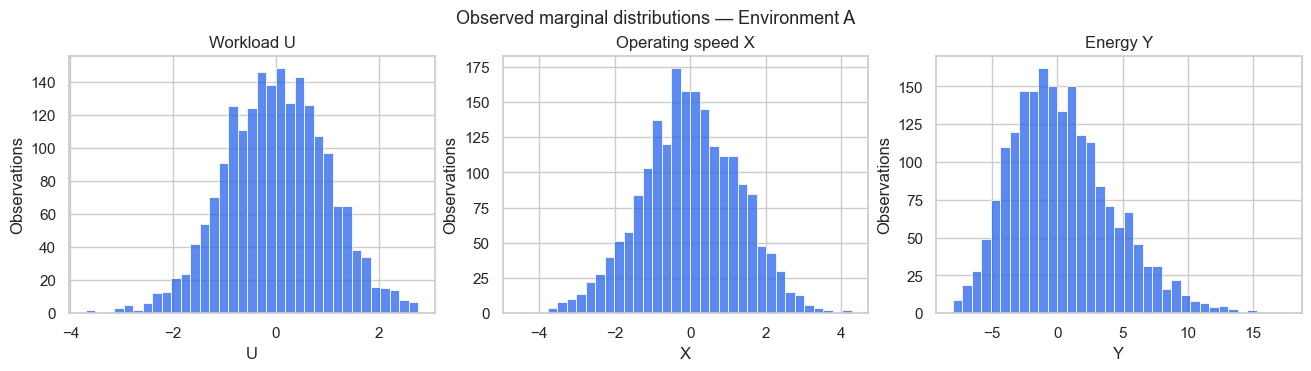

In [6]:
viz = generate_observational(2_000, "A", seed=1201)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for ax, col, label in zip(axes, ["U", "X", "Y"],
                          ["Workload U", "Operating speed X", "Energy Y"]):
    sns.histplot(viz[col], bins=35, ax=ax, color="#2563eb", edgecolor="white")
    ax.set_title(label)
    ax.set_xlabel(col)
    ax.set_ylabel("Observations")
fig.suptitle("Observed marginal distributions — Environment A", fontsize=13)
fig.savefig(FIGURES / "01_marginal_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

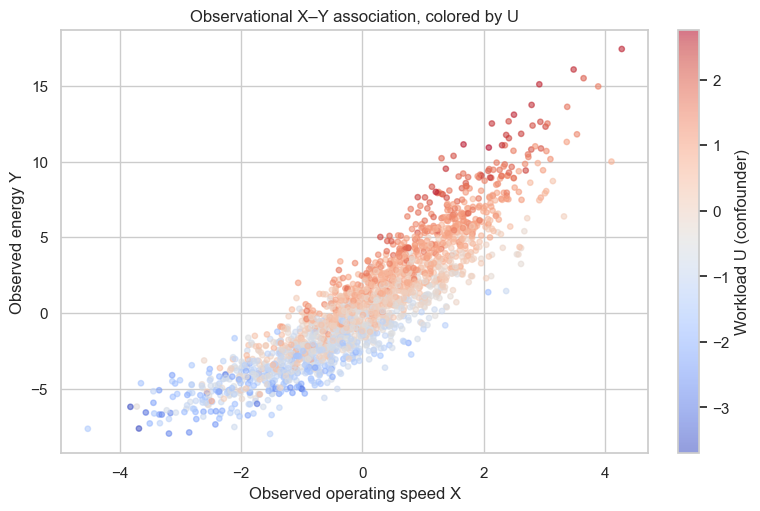

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5), constrained_layout=True)
sc = ax.scatter(viz["X"], viz["Y"], c=viz["U"], cmap="coolwarm", s=15, alpha=0.55)
fig.colorbar(sc, ax=ax, label="Workload U (confounder)")
ax.set(xlabel="Observed operating speed X", ylabel="Observed energy Y",
       title="Observational X–Y association, colored by U")
fig.savefig(FIGURES / "02_observational_scatter.png", dpi=160, bbox_inches="tight")
plt.show()

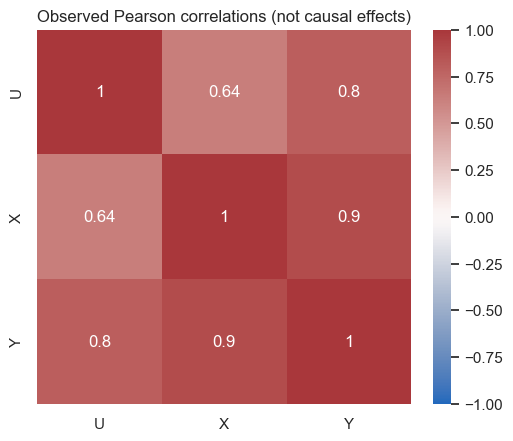

,U,X,Y
U,1.000,0.637,0.802
X,0.637,1.000,0.898
Y,0.802,0.898,1.000


In [8]:
corr = viz[["U", "X", "Y"]].corr()
fig, ax = plt.subplots(figsize=(5.3, 4.3), constrained_layout=True)
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, cmap="vlag", square=True, ax=ax)
ax.set_title("Observed Pearson correlations (not causal effects)")
fig.savefig(FIGURES / "03_correlations.png", dpi=160, bbox_inches="tight")
plt.show()
display(corr.round(3))


## Derive the exact effect of an intervention

An intervention $do(X=x)$ replaces the natural speed equation with the constant $X:=x$. It **cuts the arrow from workload to speed**, but keeps the outcome mechanism unchanged.

The resulting outcome is,

$$
Y\mid do(X=x)=2x+1.5U+0.5xU+\epsilon_Y.
$$

Averaging over the environment's workload distribution and zero-mean noise gives,

$$
\boxed{\mathbb{E}[Y\mid do(X=x)] = 2x + (1.5+0.5x)\mu_e.}
$$

For Environment A, $\mu_A=0$, so the response is $2x$. For Environment B, $\mu_B=2$, it is $3x+3$.

Changing speed from 0 to 1 gives,

$$
\underbrace{Y(1)-Y(0)}_{\mathrm{ITE}}=2+0.5U,
\qquad
\underbrace{\mathbb{E}[Y(1)-Y(0)]}_{\mathrm{ATE}}=2+0.5\mu_e.
$$

**ITE** = Individual Treatment Effect; **ATE** = Average Treatment Effect; **CATE** = Conditional Average Treatment Effect. Here, conditional on workload, $\mathrm{CATE}(u)=2+0.5u$. The exact ITE is known only because this synthetic structural equation specifies the same background disturbances across interventions.


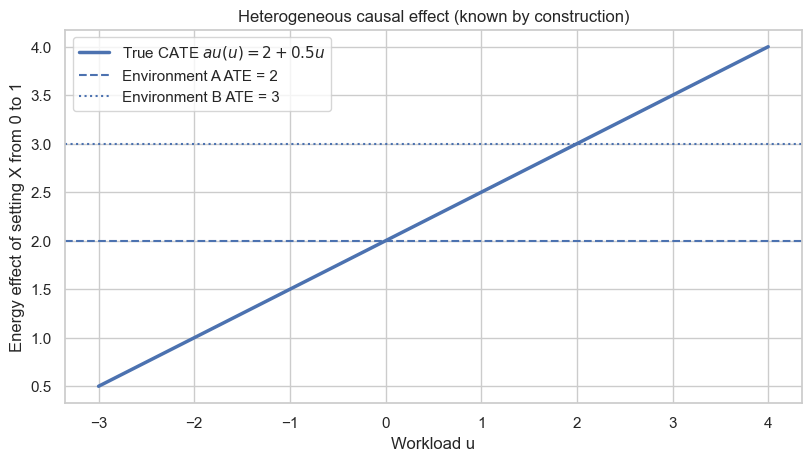

In [9]:
def interventional_mean(x, environment):
    mu = ENVIRONMENTS[environment]["load_mean"]
    return 2 * np.asarray(x) + (1.5 + 0.5 * np.asarray(x)) * mu

u_grid = np.linspace(-3, 4, 200)
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(u_grid, true_individual_effect(u_grid), label=r"True CATE $	au(u)=2+0.5u$", lw=2.5)
ax.axhline(true_population_ate("A"), ls="--", label="Environment A ATE = 2")
ax.axhline(true_population_ate("B"), ls=":", label="Environment B ATE = 3")
ax.set(xlabel="Workload u", ylabel="Energy effect of setting X from 0 to 1",
       title="Heterogeneous causal effect (known by construction)")
ax.legend()
fig.savefig(FIGURES / "04_true_causal_effect.png", dpi=160, bbox_inches="tight")
plt.show()


## Observational prediction

In Environment A,

$$
U\sim\mathcal{N}(0,1),\quad X=0.8U+\epsilon_X,
\quad \operatorname{Var}(X)=0.8^2+1=1.64.
$$

Because $(U,X)$ is jointly Gaussian,

$$
\mathbb{E}[U\mid X=x]
=\frac{\operatorname{Cov}(U,X)}{\operatorname{Var}(X)}x
=\frac{0.8}{1.64}x=\frac{20}{41}x.
$$

Substitute this into the outcome equation, using $\mathbb{E}[\epsilon_Y\mid X]=0$,

$$
\begin{aligned}
\mathbb{E}[Y\mid X=x]
&=2x+(1.5+0.5x)\mathbb{E}[U\mid X=x]\\
&=\boxed{\frac{112}{41}x+\frac{10}{41}x^2}.
\end{aligned}
$$

Therefore, **setting** speed by intervention yields $\mathbb{E}[Y\mid do(X=x)]=2x$ for Environment A.

Conditioning on observed speed also selects machines with different likely workload. Intervening on speed does *not* change the workload distribution. Therefore these two questions have different answers even with unlimited observational data.


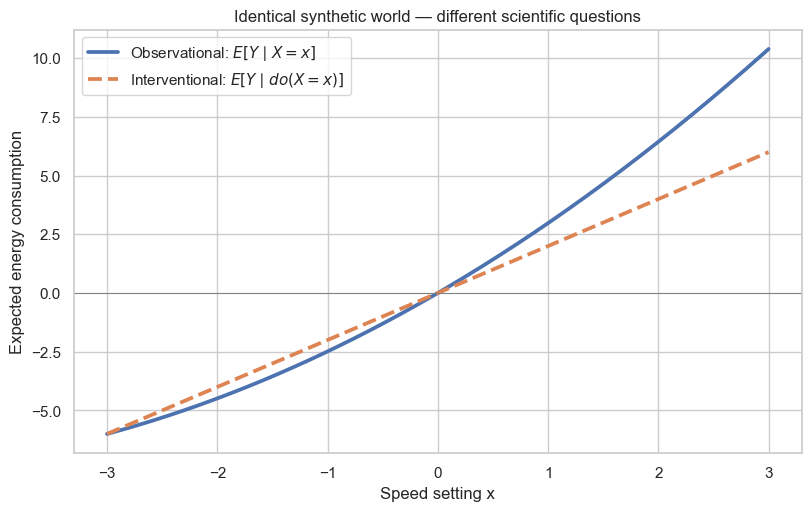

At x=1: observational expectation = 2.9756
At x=1: intervention expectation = 2.0


In [10]:
def observational_mean_env_a(x):
    x = np.asarray(x)
    return (112.0 / 41.0) * x + (10.0 / 41.0) * x**2

x_grid = np.linspace(-3, 3, 300)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.plot(x_grid, observational_mean_env_a(x_grid), lw=2.7,
        label=r"Observational: $E[Y\mid X=x]$")
ax.plot(x_grid, interventional_mean(x_grid, "A"), lw=2.7, ls="--",
        label=r"Interventional: $E[Y\mid do(X=x)]$")
ax.axhline(0, lw=0.7, color="gray")
ax.set(xlabel="Speed setting x", ylabel="Expected energy consumption",
       title="Identical synthetic world — different scientific questions")
ax.legend()
fig.savefig(FIGURES / "05_observational_vs_interventional.png", dpi=180, bbox_inches="tight")
plt.show()
print("At x=1: observational expectation =", round(float(observational_mean_env_a(1)), 4))
print("At x=1: intervention expectation =", round(float(interventional_mean(1, "A")), 4))


## Generate actual randomized intervention data

The formulas above are *analytic*. We also want to simulate interventions explicitly to confirm them independently.

When we run a randomized intervention, we sample workload and outcome noise as usual, but do not use the natural equation for speed. Instead we set $X=x$ for everyone.

Observational rows and intervention rows are kept in separate files, so later models cannot accidentally confuse data from distinct regimes.


In [11]:
def generate_intervention(n, environment="A", do_x=0.0, seed=2026):
    rng = np.random.default_rng(seed)
    cfg = ENVIRONMENTS[environment]
    u = rng.normal(cfg["load_mean"], cfg["load_sd"], n)
    eps_y = rng.normal(0, PARAMETERS["outcome_noise_sd"], n)
    x = np.full(n, float(do_x))
    y = structural_outcome(x, u, eps_y)
    return pd.DataFrame({"U": u, "X": x, "Y": y,
                         "regime": f"do(X={do_x:g})"})

rows = []
for env in ENVIRONMENTS:
    for do_x in (0.0, 1.0):
        trial = generate_intervention(30_000, env, do_x, seed=9000 + int(do_x) + (100 if env == "B" else 0))
        empirical = float(trial["Y"].mean())
        exact = float(interventional_mean(do_x, env))
        rows.append({"environment": env, "intervention": f"do(X={do_x:g})",
                     "simulated_mean": empirical, "theoretical_mean": exact,
                     "absolute_MC_error": abs(empirical - exact)})
summary = pd.DataFrame(rows)
display(summary.round(4))
assert summary["absolute_MC_error"].max() < 0.08, "Unexpectedly large Monte Carlo discrepancy"
print("PASS: Randomized intervention means agree with theoretical means to sampling accuracy")

,environment,intervention,simulated_mean,theoretical_mean,absolute_MC_error
0,A,do(X=0),0.0004,0.0,0.0004
1,A,do(X=1),1.9981,2.0,0.0019
2,B,do(X=0),3.0049,3.0,0.0049
3,B,do(X=1),5.9858,6.0,0.0142


PASS: Randomized intervention means agree with theoretical means to sampling accuracy



## Compare environments without changing the underlying causal law

**Environment A:** $U\sim\mathcal{N}(0,1)$.  
**Environment B:** $U\sim\mathcal{N}(2,1)$.

We change only the *distribution of workload*, not the structural equations for speed or energy. This is a **population/distribution shift**, not a change to the outcome mechanism.

Because the effect $2+0.5U$ depends on workload, the **population ATE** changes even though the underlying effect function $\tau(u)$ is unchanged:

- Environment A: ATE = 2.
- Environment B: ATE = 3.

Later, this will allow us to ask whether a model trained in one environment can correctly estimate effects in another. We are **not yet testing a fitted model**.


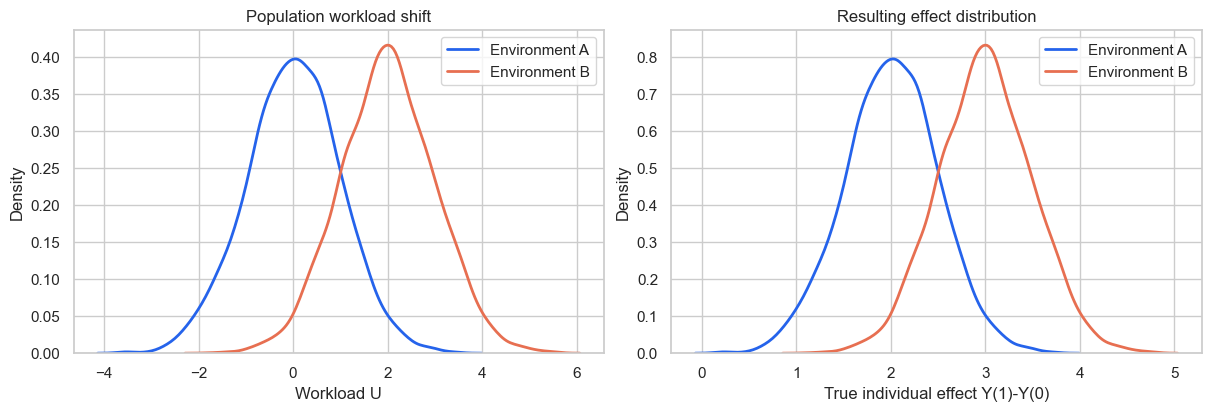

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for env, color in (("A", "#2563eb"), ("B", "#e76f51")):
    d = generate_observational(5_000, env, seed=1301 if env == "A" else 1302)
    sns.kdeplot(d["U"], ax=axes[0], label=f"Environment {env}", color=color, lw=2)
    sns.kdeplot(d["tau_true"], ax=axes[1], label=f"Environment {env}", color=color, lw=2)
axes[0].set(xlabel="Workload U", title="Population workload shift")
axes[1].set(xlabel="True individual effect Y(1)-Y(0)", title="Resulting effect distribution")
for ax in axes: ax.legend()
fig.savefig(FIGURES / "06_environment_shift.png", dpi=160, bbox_inches="tight")
plt.show()


## Create reproducible training, validation, and test files

We use three sample sizes $n\in\{500,2000,10000\}$ **per environment**. For each, we independently generate:

- `train`: $n$ rows;
- `validation`: $\max(200,\lfloor0.2n\rfloor)$ rows;
- `test`: $\max(300,\lfloor0.3n\rfloor)$ rows.

These are **independent samples**, not random slices of one generated table. Seeds are constructed deterministically and recorded. We save:

- `*_observed.csv` — ONLY `U, X, Y` for downstream learning;
- `*_oracle.csv` — all columns including disturbances and ground-truth potential outcomes for evaluation only.


In [13]:
SAMPLE_SIZES = (500, 2_000, 10_000)
SPLITS = ("train", "validation", "test")
SEED_BASE = 20261026
manifest = []

for env_i, env in enumerate(ENVIRONMENTS):
    for size_i, train_n in enumerate(SAMPLE_SIZES):
        counts = {"train": train_n,
                  "validation": max(200, int(train_n * 0.2)),
                  "test": max(300, int(train_n * 0.3))}
        for split_i, split in enumerate(SPLITS):
            seed = SEED_BASE + env_i * 100_000 + size_i * 10_000 + split_i * 1_000
            df = generate_observational(counts[split], env, seed)
            stem = f"env_{env}_n{train_n}_{split}"
            observed_path = DATA / f"{stem}_observed.csv"
            oracle_path = DATA / f"{stem}_oracle.csv"
            df[["U", "X", "Y"]].to_csv(observed_path, index=False)
            df.to_csv(oracle_path, index=False)
            manifest.append({"environment": env, "training_sample_size": train_n,
                             "split": split, "rows": len(df), "seed": seed,
                             "observed_file": observed_path.name,
                             "oracle_file": oracle_path.name})

manifest_df = pd.DataFrame(manifest)
display(manifest_df.head(9))
print("Observational CSV files:", len(manifest) * 2)

,environment,training_sample_size,split,rows,seed,observed_file,oracle_file
0,A,500,train,500,20261026,env_A_n500_train_observed.csv,env_A_n500_train_oracle.csv
1,A,500,validation,200,20262026,env_A_n500_validation_observed.csv,env_A_n500_validation_oracle.csv
2,A,500,test,300,20263026,env_A_n500_test_observed.csv,env_A_n500_test_oracle.csv
3,A,2000,train,2000,20271026,env_A_n2000_train_observed.csv,env_A_n2000_train_oracle.csv
4,A,2000,validation,400,20272026,env_A_n2000_validation_observed.csv,env_A_n2000_validation_oracle.csv
5,A,2000,test,600,20273026,env_A_n2000_test_observed.csv,env_A_n2000_test_oracle.csv
6,A,10000,train,10000,20281026,env_A_n10000_train_observed.csv,env_A_n10000_train_oracle.csv
7,A,10000,validation,2000,20282026,env_A_n10000_validation_observed.csv,env_A_n10000_validation_oracle.csv
8,A,10000,test,3000,20283026,env_A_n10000_test_observed.csv,env_A_n10000_test_oracle.csv


Observational CSV files: 36



## Save intervention test sets

We also save intervention datasets at $X=0$ and $X=1$ for each environment. These are kept out of the observational training files, and they can later be used as an explicit external evaluation regime.


In [14]:
intervention_manifest = []
for env_i, env in enumerate(ENVIRONMENTS):
    for intervention_i, do_x in enumerate((0.0, 1.0)):
        seed = SEED_BASE + 500_000 + env_i * 10_000 + intervention_i * 1_000
        intervention_df = generate_intervention(10_000, env, do_x, seed)
        name = f"env_{env}_do_X_{int(do_x)}_test.csv"
        intervention_df.to_csv(DATA / name, index=False)
        intervention_manifest.append({"environment": env, "do_x": do_x,
                                      "rows": len(intervention_df), "seed": seed, "file": name})
metadata = {"study": "Synthetic causal machine benchmark V1",
            "parameter_values": PARAMETERS,
            "environments": ENVIRONMENTS,
            "independence": "U, epsilon_X, epsilon_Y generated independently",
            "causal_graph_edges": [["U", "X"], ["U", "Y"], ["X", "Y"]],
            "outcome_equation": "Y = 2 X + 1.5 U + 0.5 X U + epsilon_Y",
            "speed_equation": "X = 0.8 U + epsilon_X",
            "true_ite_0_to_1": "2 + 0.5 U",
            "true_ate_0_to_1": {e: true_population_ate(e) for e in ENVIRONMENTS},
            "observational_splits": manifest,
            "intervention_tests": intervention_manifest,
            "learner_columns": ["U", "X", "Y"],
            "oracle_only_columns": ["epsilon_X", "epsilon_Y", "Y0", "Y1", "tau_true"],
            "limitations": ["Abstract standardized units", "Observed confounder only",
                            "Simple polynomial mechanisms", "Normal independent disturbances",
                            "Not real machine measurements"]}
with open(OUTPUT / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
manifest_df.to_csv(OUTPUT / "dataset_manifest.csv", index=False)
print("Saved metadata.json and dataset_manifest.csv")
print("Files in data/:", len(list(DATA.glob("*.csv"))))

Saved metadata.json and dataset_manifest.csv
Files in data/: 40


We verify that saved files can be read, have correct schemas, contain no missing values, and do not expose oracle answers to learner-facing files.

In [16]:
assert len(manifest_df) == 18
assert len(list(DATA.glob("*.csv"))) == 40  # 36 observational (observed+oracle) + 4 interventions
for row in manifest:
    learner = pd.read_csv(DATA / row["observed_file"])
    oracle = pd.read_csv(DATA / row["oracle_file"])
    assert list(learner.columns) == ["U", "X", "Y"]
    assert list(oracle.columns) == ["U", "X", "Y", "epsilon_X", "epsilon_Y", "Y0", "Y1", "tau_true"]
    assert len(learner) == len(oracle) == row["rows"]
    assert not learner.isna().any().any() and not oracle.isna().any().any()
    np.testing.assert_allclose(oracle["tau_true"], true_individual_effect(oracle["U"]))
for row in intervention_manifest:
    d = pd.read_csv(DATA / row["file"])
    assert np.all(d["X"] == row["do_x"])
    assert len(d) == row["rows"]
print("ALL CHECKS PASSED")
print("Figures:", len(list(FIGURES.glob("*.png"))))
print("Data CSVs:", len(list(DATA.glob("*.csv"))))

ALL CHECKS PASSED
Figures: 6
Data CSVs: 40
